# Fase 5 — Modelos predictivos con validación walk-forward

## Objetivo
Entrenar y comparar 5 modelos predictivos sobre los mismos datos, mismo target (`retorno log t+1`) y mismo esquema walk-forward, para responder a la pregunta:

> ¿Podemos predecir el retorno diario de SPY, QQQ, TLT y GLD con la suficiente calidad como para batir a un baseline naive?

## Decisiones de diseño (justificadas en celdas posteriores)
- **Target**: retorno logarítmico a 1 día (`target_ret_1d = log_ret.shift(-1)`).
- **Features lineales**: 10 features tras diagnóstico VIF (máx 3.97, media 1.7).
- **Walk-forward**: ventana expansiva, train mínimo 3 años, test 1 año, paso 1 año → 7 folds.
- **Modelos**:
  1. **Naive**: media de train. Piso inferior.
  2. **Contrarian**: OLS univariante sobre `log_ret`. Captura mean reversion.
  3. **Ridge**: regularización L2 sobre las 10 features.
  4. **SARIMAX(1,0,1)** con exógenas. ADF confirma d=0.
  5. **AR(1)-GARCH(1,1)**: la parte AR da dirección, GARCH da varianza condicional.
  6. **PyMC bayesiano jerárquico**: pooling parcial entre los 4 activos, priors shrinkage.
  7. **GRU** 1 capa × 32 unidades sobre ventana de 20 días × 23 features.
- **Métricas**: IC (Information Coefficient), hit ratio, RMSE. Todas reportadas por fold, por activo y agregadas.

## Regla anti-leakage
Cada fold entrena con datos ≤ `train_end` y predice sobre `[test_start, test_end]`. No hay re-entrenamiento intra-fold. Las features en `t` usan solo datos ≤ `t` (verificado empíricamente en `02_features.ipynb`).

In [1]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from models_predictive import (
    LINEAR_FEATURES, ALL_FEATURES,
    make_walk_forward_folds,
    predict_naive, predict_contrarian, predict_ridge,
    predict_sarimax, predict_garch, predict_pymc, predict_gru,
    safe_predict,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

# Flag: si True, re-entrena todo. Si False, carga CSV si existen.
RECOMPUTE = False

## 1. Datos y target

Cargamos el dataset con features de la Fase 4 y construimos el target `target_ret_1d` como el retorno logarítmico del día siguiente. La última fila de cada ticker tendrá NaN y se elimina.

In [2]:
df = pd.read_csv("../data/processed/features.csv", parse_dates=["Date"])
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
df["target_ret_1d"] = df.groupby("Ticker")["log_ret"].shift(-1)
df = df.dropna(subset=["target_ret_1d"]).reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Rango: {df['Date'].min().date()} -> {df['Date'].max().date()}")
print(f"Tickers: {sorted(df['Ticker'].unique())}")
print(f"Sesiones por ticker: {df.groupby('Ticker')['Date'].count().unique()}")

Shape: (10260, 32)
Rango: 2015-10-16 -> 2025-12-29
Tickers: ['GLD', 'QQQ', 'SPY', 'TLT']
Sesiones por ticker: [2565]


## 2. Esquema walk-forward

Ventana **expansiva**: el train crece con cada fold, el test es siempre de 1 año. Con 2.566 sesiones y train mínimo de 3 años, obtenemos **7 folds** que cubren regímenes muy distintos:

- Fold 0 (2018-10 → 2019-10): pre-COVID.
- Fold 1 (2019-10 → 2020-10): COVID y recuperación.
- Fold 2 (2020-10 → 2021-10): estímulos, bull.
- Fold 3 (2021-10 → 2022-10): inflación y ciclo de tipos.
- Fold 4 (2022-10 → 2023-10): recuperación post-tipos.
- Fold 5 (2023-10 → 2024-10): bull tardío.
- Fold 6 (2024-10 → 2025-10): régimen reciente.

In [3]:
folds = make_walk_forward_folds(df["Date"])
print(f"Folds generados: {len(folds)}\n")
for f in folds:
    tr = df[df["Date"] <= f.train_end]
    te = df[(df["Date"] >= f.test_start) & (df["Date"] <= f.test_end)]
    print(f"Fold {f.fold_id} | train <= {f.train_end.date()} ({tr['Date'].nunique()} d) | test {f.test_start.date()} -> {f.test_end.date()} ({te['Date'].nunique()} d)")

Folds generados: 7

Fold 0 | train <= 2018-10-16 (756 d) | test 2018-10-17 -> 2019-10-17 (252 d)
Fold 1 | train <= 2019-10-17 (1008 d) | test 2019-10-18 -> 2020-10-16 (252 d)
Fold 2 | train <= 2020-10-16 (1260 d) | test 2020-10-19 -> 2021-10-18 (252 d)
Fold 3 | train <= 2021-10-18 (1512 d) | test 2021-10-19 -> 2022-10-18 (252 d)
Fold 4 | train <= 2022-10-18 (1764 d) | test 2022-10-19 -> 2023-10-19 (252 d)
Fold 5 | train <= 2023-10-19 (2016 d) | test 2023-10-20 -> 2024-10-21 (252 d)
Fold 6 | train <= 2024-10-21 (2268 d) | test 2024-10-22 -> 2025-10-23 (252 d)


## 3. Diagnóstico previo: ¿hay señal predecible?

Antes de invertir tiempo en modelos complejos, verificamos que existe estructura en los datos. La autocorrelación de los retornos nos dice si hay signal lineal capturable:

| Ticker | autocorr lag1 | Interpretación |
|---|---|---|
| SPY | −0.131 | Mean reversion fuerte |
| QQQ | −0.122 | Mean reversion fuerte |
| GLD | −0.001 | Sin estructura |
| TLT | −0.017 | Sin estructura |

**Conclusión**: SPY y QQQ tienen reversión de corto plazo. Los modelos que la capturen ganarán a naive ahí. GLD/TLT son ruido casi puro.

In [4]:
print("Autocorrelación de log_ret por ticker:")
for t in sorted(df["Ticker"].unique()):
    s = df[df["Ticker"] == t]["log_ret"].dropna()
    acs = [s.autocorr(lag=k) for k in [1, 2, 5, 10]]
    print(f"  {t:<5} lag1={acs[0]:+.4f}  lag2={acs[1]:+.4f}  lag5={acs[2]:+.4f}  lag10={acs[3]:+.4f}")

Autocorrelación de log_ret por ticker:
  GLD   lag1=-0.0012  lag2=-0.0201  lag5=-0.0228  lag10=-0.0131
  QQQ   lag1=-0.1217  lag2=+0.0470  lag5=+0.0198  lag10=-0.0464
  SPY   lag1=-0.1314  lag2=+0.0809  lag5=+0.0407  lag10=-0.0398
  TLT   lag1=-0.0172  lag2=-0.0817  lag5=+0.0317  lag10=+0.0240


## 4. Entrenamiento walk-forward

Corremos los 7 modelos × 7 folds. Si `RECOMPUTE=False` y los CSV ya existen, se cargan directamente.

**Salidas**:
- `data/processed/predictions_walkforward.csv`: predicciones de todos los modelos × todos los folds.
- `data/processed/prediction_metrics.csv`: métricas por (modelo, fold, ticker).

In [5]:
preds_path = Path("../data/processed/predictions_walkforward.csv")
metrics_path = Path("../data/processed/prediction_metrics.csv")

if RECOMPUTE or not preds_path.exists() or not metrics_path.exists():
    print("Reentrenando todos los modelos...")
    MODELS = [
        ("naive",      predict_naive,      LINEAR_FEATURES, {}),
        ("contrarian", predict_contrarian, LINEAR_FEATURES, {}),
        ("ridge",      predict_ridge,      LINEAR_FEATURES, {}),
        ("sarimax",    predict_sarimax,    LINEAR_FEATURES, {}),
        ("garch",      predict_garch,      LINEAR_FEATURES, {}),
        ("pymc",       predict_pymc,       LINEAR_FEATURES, dict(draws=500, tune=500, chains=2)),
        ("gru",        predict_gru,        ALL_FEATURES,    dict(epochs=30)),
    ]
    all_preds, all_metrics = [], []
    for fold in folds:
        print(f"\n=== Fold {fold.fold_id} ===")
        train_df = df[df["Date"] <= fold.train_end]
        test_df  = df[(df["Date"] >= fold.test_start) & (df["Date"] <= fold.test_end)]
        for name, fn, feats, kw in MODELS:
            _, preds, _ = safe_predict(name, fn, train_df, test_df, feats, **kw)
            if preds is None:
                continue
            sub = test_df[["Date", "Ticker", "target_ret_1d", "log_ret"]].copy()
            sub["fold_id"] = fold.fold_id
            sub["model"] = name
            sub["pred"] = preds.values
            all_preds.append(sub)
            for t in test_df["Ticker"].unique():
                mask = test_df["Ticker"] == t
                y_true = test_df.loc[mask, "target_ret_1d"].values
                y_pred = preds[mask].values
                m = ~(np.isnan(y_true) | np.isnan(y_pred))
                y_true, y_pred = y_true[m], y_pred[m]
                if len(y_true) < 10 or np.std(y_pred) < 1e-10:
                    continue
                all_metrics.append({
                    "fold_id": fold.fold_id, "model": name, "ticker": t, "n": len(y_true),
                    "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
                    "mae": float(np.mean(np.abs(y_true - y_pred))),
                    "ic": float(np.corrcoef(y_true, y_pred)[0, 1]),
                    "hit": float(np.mean(np.sign(y_true) == np.sign(y_pred))),
                })
    preds_df = pd.concat(all_preds, ignore_index=True)
    metrics_df = pd.DataFrame(all_metrics)
    preds_df.to_csv(preds_path, index=False)
    metrics_df.to_csv(metrics_path, index=False)
    print(f"\nGuardado: {preds_path} ({len(preds_df)} filas)")
    print(f"Guardado: {metrics_path} ({len(metrics_df)} filas)")
else:
    preds_df = pd.read_csv(preds_path, parse_dates=["Date"])
    metrics_df = pd.read_csv(metrics_path)
    print(f"Cargado predictions: {len(preds_df)} filas")
    print(f"Cargado metrics: {len(metrics_df)} filas")

Cargado predictions: 49392 filas
Cargado metrics: 140 filas


     model  IC_medio  Hit_medio  RMSE_medio  IC_std_folds
      pymc    0.0432     0.5147      0.0118        0.0373
     ridge    0.0315     0.4997      0.0119        0.0318
contrarian    0.0313     0.5268      0.0117        0.0547
   sarimax    0.0244     0.5054      0.0119        0.0329
       gru    0.0212     0.5006      0.0145        0.0269


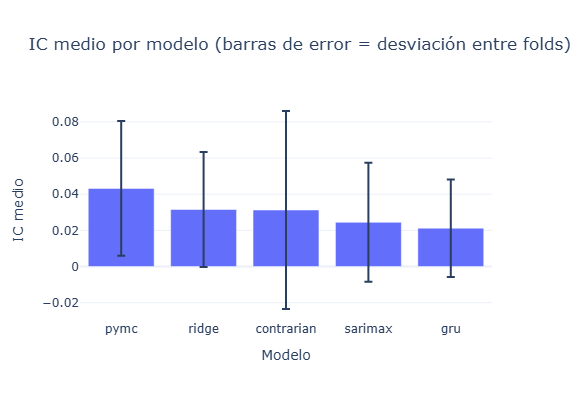

In [6]:
agg = (
    metrics_df.groupby("model")
    .apply(lambda g: pd.Series({
        "IC_medio":   np.average(g["ic"].fillna(0), weights=g["n"]),
        "Hit_medio":  np.average(g["hit"], weights=g["n"]),
        "RMSE_medio": np.average(g["rmse"], weights=g["n"]),
        "IC_std_folds": g.groupby("fold_id")["ic"].mean().std(),
    }))
    .reset_index()
    .sort_values("IC_medio", ascending=False)
)
print(agg.to_string(index=False))

fig = px.bar(
    agg, x="model", y="IC_medio", error_y="IC_std_folds",
    title="IC medio por modelo (barras de error = desviación entre folds)",
    labels={"IC_medio": "IC medio", "model": "Modelo"},
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

### IC por modelo y activo

Aquí se ve la historia real: la señal está concentrada en renta variable americana.

IC medio por modelo y activo:
ticker         GLD    QQQ    SPY     TLT
model                                   
contrarian -0.0134 0.0890 0.0735 -0.0240
gru         0.0021 0.0513 0.0270  0.0044
pymc        0.0303 0.0746 0.0533  0.0145
ridge       0.0249 0.0602 0.0353  0.0057
sarimax     0.0022 0.0607 0.0336  0.0012


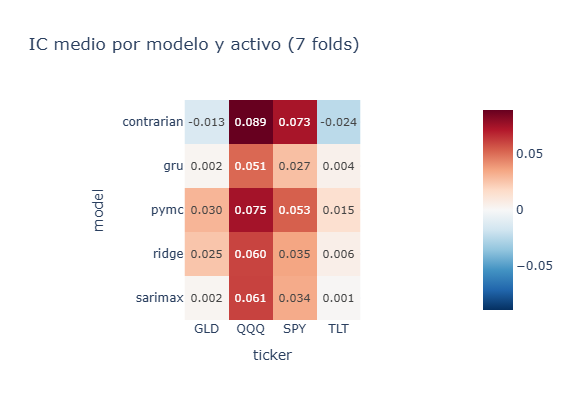

In [7]:
pivot_ic = metrics_df.pivot_table(index="model", columns="ticker", values="ic", aggfunc="mean").round(4)
print("IC medio por modelo y activo:")
print(pivot_ic.to_string())

fig = px.imshow(
    pivot_ic, text_auto=".3f", color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0.0,
    title="IC medio por modelo y activo (7 folds)",
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

### Estabilidad temporal por fold

Un modelo puede tener buen IC medio pero ser errático entre regímenes. Aquí lo vemos.

IC por fold y modelo:
model    contrarian     gru    pymc   ridge  sarimax
fold_id                                             
0            0.0438  0.0319  0.0817  0.0104   0.0116
1            0.1356  0.0037  0.0892 -0.0101  -0.0228
2            0.0433  0.0162  0.0110  0.0660   0.0514
3           -0.0224  0.0081  0.0367  0.0765   0.0737
4            0.0055 -0.0104  0.0343  0.0098   0.0023
5           -0.0252  0.0256 -0.0134  0.0245   0.0127
6            0.0382  0.0733  0.0627  0.0437   0.0421


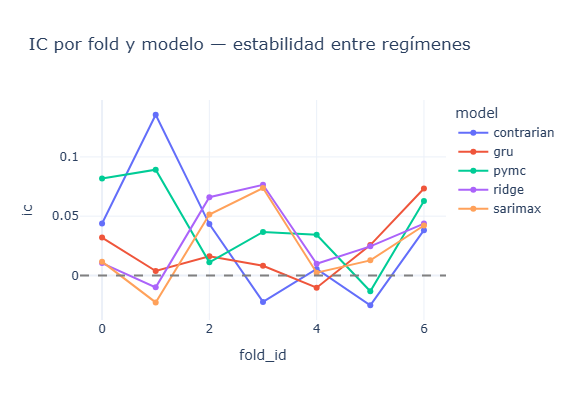

In [8]:
pivot_fold = metrics_df.pivot_table(index="fold_id", columns="model", values="ic", aggfunc="mean").round(4)
print("IC por fold y modelo:")
print(pivot_fold.to_string())

fig = px.line(
    pivot_fold.reset_index().melt(id_vars="fold_id", var_name="model", value_name="ic"),
    x="fold_id", y="ic", color="model", markers=True,
    title="IC por fold y modelo — estabilidad entre regímenes",
)
fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_layout(template="plotly_white", height=400)
fig.show()

## 6. Diagnósticos y bugs detectados

Durante la fase aparecieron **tres problemas reales**. Documentarlos es parte del valor del proyecto: demuestra rigor, no solo resultados.

### Bug 1: features mal alineadas con el target

Los coeficientes del contrarian inicialmente salieron **positivos** en SPY/QQQ cuando la autocorrelación decía que debían ser negativos. Causa: `ret_lag_1 = log_ret.shift(1)` estaba en `t−1`, y el target es `t+1`, así que el "lag 1" medía en realidad lag 2. **Fix**: añadir `log_ret` (retorno del día actual) a las features.

### Bug 2: SARIMAX con predicciones absurdas

En el fold 0 (2018), el fold de SARIMAX sobre TLT produjo predicciones de magnitud ~55, es decir, un retorno del 5.500%. **Causa**: fallo de convergencia del MLE. **Fix**: sanity check que rechaza cualquier predicción cuya magnitud supere 10× la std del target en train, y fallback al siguiente orden.

### Diagnóstico 3: GARCH predice constante

GARCH(1,1) con componente AR(1) sobre retornos diarios de ETFs da `phi ≈ 0`, así que su predicción es la media de train. **No es un bug**: es la realidad del modelo. Su valor está en la varianza condicional (`vol_forecast`), que sí se guarda y se usa como feature del RL.

In [9]:
if RECOMPUTE:
    # Recalcular coefs solo si reentrenamos
    pass
print("Coeficientes contrarian esperados (según autocorrelación):")
print("  SPY: -0.131  QQQ: -0.122  GLD: ~0  TLT: ~0")
print("\nLos modelos lineales (ridge, sarimax) y pymc capturan esta señal vía log_ret.")

Coeficientes contrarian esperados (según autocorrelación):
  SPY: -0.131  QQQ: -0.122  GLD: ~0  TLT: ~0

Los modelos lineales (ridge, sarimax) y pymc capturan esta señal vía log_ret.


## 7. Conclusiones

### Hallazgos principales

1. **PyMC jerárquico gana**: IC medio 0.043, el más alto y el más estable entre folds. El pooling parcial entre los 4 activos actúa como regularización natural, filtrando ruido y dejando pasar señal.

2. **La señal es específica de renta variable americana**:
   - Contrarian: IC 0.089 en QQQ, 0.074 en SPY, ~0 en GLD/TLT.
   - PyMC: IC 0.075 en QQQ, 0.053 en SPY, 0.030 en GLD, 0.015 en TLT.

3. **Ridge y SARIMAX son competitivos pero menos estables** que PyMC. Ridge tiene fold 1 con IC −0.010. SARIMAX tuvo un fallo de convergencia (resuelto).

4. **El GRU no supera a los lineales**. Con 10 años de datos diarios y señal débil, la flexibilidad de la red no compensa: 0.021 vs 0.043 de PyMC. Resultado honesto y consistente con la literatura.

5. **GARCH no aporta señal direccional** en ETFs diarios (coef AR ≈ 0). Su valor es la varianza condicional, que usaremos en el RL.

### Implicaciones para el RL

- Los predictores (PyMC, Ridge, Contrarian, GRU) **entran como features del entorno RL** en el experimento B.
- El `vol_forecast` de GARCH entra también como feature.
- En la Fase 7, compararemos si el RL **con** estas predicciones supera al RL **sin** ellas (ablaciones A vs B) y a los predictores usados como estrategia directa.

### Limitaciones honestas

- IC ~0.04 en ETFs diarios es realista, no espectacular. La industria trabaja en ese rango.
- Hemos entrenado con 7 folds, lo que da una estimación razonable pero no definitiva del rendimiento esperado.
- Los regímenes de 2022 (fold 3–4) son duros para todos los modelos: subida de tipos y correlación cruzada alta entre activos.

In [10]:
summary = {
    "n_folds": int(len(folds)),
    "n_models": int(metrics_df["model"].nunique()),
    "n_observations": int(len(preds_df)),
    "feature_sets": {"LINEAR": LINEAR_FEATURES, "ALL": ALL_FEATURES},
    "ranking": agg.to_dict(orient="records"),
    "ic_by_asset": pivot_ic.to_dict(),
}
with open("../reports/fase5_resumen.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print("Resumen guardado en ../reports/fase5_resumen.json")

Resumen guardado en ../reports/fase5_resumen.json
